<a href="https://colab.research.google.com/github/VictoriaO26/AI-assisted-Cloud-Infrastructure-Cybersecurity-Bootcamp/blob/main/Authorization_and_Automated_Access_Control_in_Cloud_CI_notebook_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 2: AI-Assisted Authorization and Automated Access Control in Cloud CI


**Objective**: Students will learn to build, evaluate, and interpret machine learning and deep learning models for cloud authorization prediction, including how to preprocess access control data, predict authorization decisions, and assess model performance in the context of cloud identity and access management (IAM).

**Acknowledgement**: This module was developed under the National Science Foundation awards # 2416990, 2416992 and 2607393 at Tennessee Tech University, North Carolina A&T State University and University at Albany.



### Cloud Authorization Prediction Architecture

Cloud authorization systems generate large volumes of access requests from users, applications, and cloud services. Machine learning can assist Identity and Access Management (IAM) by analyzing historical authorization records and predicting whether a new access request should be approved or denied. Instead of relying solely on manually defined policies, AI models learn patterns from previous authorization decisions to identify legitimate and potentially unauthorized requests. This approach improves the scalability, consistency, and efficiency of access control in modern cloud environments while supporting security principles such as least privilege and zero trust.

**Implementation Workflow**

**Dataset Preparation**: Load the historical cloud authorization dataset containing user, resource, action, environmental attributes, and authorization decisions.

**Data Preprocessing**: Clean the dataset, encode categorical attributes, normalize numerical features if required, and split the data into training and testing sets.

**Model Development**: Train both a Machine Learning model (e.g., Random Forest, Decision Trees, Support Vector Machines) and a Deep Learning model to learn authorization patterns from historical access requests.

**Model Evaluation**: Evaluate each model using security-oriented metrics such as accuracy, precision, recall, F1-score, and confusion matrix to measure authorization prediction performance.

**Authorization Prediction**: Use the trained models to classify new access requests as Allow or Deny, demonstrating how AI can support automated authorization decisions in cloud Identity and Access Management (IAM) systems.

## Cloud CI scenario

Imagine you are working as a cloud security engineer for a cloud-native organization. Developers, service accounts, and CI/CD workflows continuously request access to cloud resources.

Examples include:

- Developer → Start EC2 instance
- GitHub Actions workflow → Deploy application to production
- Kubernetes service account → Read secret
- User → Delete storage bucket

Every request must be evaluated as either **Allow** or **Deny**.

In a real cloud system, these decisions may be enforced by AWS IAM, Azure RBAC, Google Cloud IAM, Kubernetes RBAC, or CI/CD platform permissions. In this lab, we use a public historical access-control dataset and treat each row as an authorization record.

## 1. Colab setup

This notebook is designed to run entirely in Google Colab. No VM, container, CyberRange, or local installation is required.

The required libraries are used for:

- data analysis: `pandas`, `numpy`
- visualization: `matplotlib`, `seaborn`
- machine learning: `scikit-learn`
- deep learning: `tensorflow`

In [ ]:
# Most required packages are already available in Google Colab.
# This command ensures scikit-learn and TensorFlow are available.
!pip install -q pandas numpy scikit-learn matplotlib seaborn tensorflow

In [ ]:
# Data unzipping
import requests
import zipfile
import io
import os

# Data analysis
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train/test split and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine learning models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    balanced_accuracy_score,
    classification_report
)

# Class weights for deep learning
from sklearn.utils.class_weight import compute_class_weight

# Deep learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

## 2. Understanding the dataset

The dataset used in this lab is the **Amazon Employee Access Challenge** dataset from Kaggle.

Each row represents a historical authorization request. The target column is `ACTION`:

- `ACTION = 1` → access approved / **Allow**
- `ACTION = 0` → access denied / **Deny**

Although the dataset comes from enterprise employee access records, the structure is similar to Cloud CI authorization data:

| Dataset concept | Cloud CI interpretation |
|---|---|
| Employee/user information | Principal metadata |
| Role fields | IAM role / job role / service identity |
| Department fields | Team, project, or organization metadata |
| Resource | Cloud resource |
| ACTION | Authorization decision: Allow or Deny |

The purpose of the lab is not to deploy a real IAM system. The purpose is to understand how historical authorization records can be used to train automated access-control models.

#### Download the file from the github

In [ ]:
# GitHub raw ZIP file URL
url = "https://github.com/acr-research-lab/AI4SecureCI/raw/main/module_2/data.zip"

# Download the zip file
response = requests.get(url)
response.raise_for_status()

# Unzip the file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(".")

# Check extracted files
for root, dirs, files in os.walk("."):
    for file in files:
        print(os.path.join(root, file))

# Load train.csv from the extracted data directory
df = pd.read_csv("train.csv")

# Display first rows
print(df.shape)
df.head()

./train.csv
./test.csv
./.config/.last_survey_prompt.yaml
./.config/.last_opt_in_prompt.yaml
./.config/gce
./.config/config_sentinel
./.config/default_configs.db
./.config/.last_update_check.json
./.config/active_config
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/configurations/config_default
./.config/logs/2026.10.26/22.18.45.880512.log
./.config/logs/2026.10.26/22.18.53.588181.log
./.config/logs/2026.10.26/22.18.38.571729.log
./.config/logs/2026.10.26/22.18.44.768076.log
./.config/logs/2026.10.26/22.18.15.518759.log
./.config/logs/2026.10.26/22.18.52.867204.log
./sample_data/anscombe.json
./sample_data/README.md
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/california_housing_test.csv
./sample_data/california_housing_train.csv
(32769, 10)


,ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
0,1,39353,85475,117961,118300,123472,117905,117906,290919,117908
1,1,17183,1540,117961,118343,123125,118536,118536,308574,118539
2,1,36724,14457,118219,118220,117884,117879,267952,19721,117880
3,1,36135,5396,117961,118343,119993,118321,240983,290919,118322
4,1,42680,5905,117929,117930,119569,119323,123932,19793,119325


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the historical authorization records before training models.

In an access-control setting, EDA helps answer questions such as:

- How many authorization records are available?
- What attributes describe each request?
- Are there missing values?
- How many requests were allowed versus denied?

This step is important because the quality and distribution of historical authorization records directly affect the behavior of the automated authorization model.

In [ ]:
# TODO: Print the dataset shape.

# TODO 1: Print the column names.
print("\nColumns:")
print(df.columns.tolist())

# TODO 2: Display the first five rows.
display(df.head())

# TODO 3: Check missing values.
print("\nMissing values per column:")
display(df.isnull().sum())

# TODO 4: Display basic statistics.
print("\nBasic statistics:")
display(df.describe())



Columns:
['ACTION', 'RESOURCE', 'MGR_ID', 'ROLE_ROLLUP_1', 'ROLE_ROLLUP_2', 'ROLE_DEPTNAME', 'ROLE_TITLE', 'ROLE_FAMILY_DESC', 'ROLE_FAMILY', 'ROLE_CODE']


,ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
0,1,39353,85475,117961,118300,123472,117905,117906,290919,117908
1,1,17183,1540,117961,118343,123125,118536,118536,308574,118539
2,1,36724,14457,118219,118220,117884,117879,267952,19721,117880
3,1,36135,5396,117961,118343,119993,118321,240983,290919,118322
4,1,42680,5905,117929,117930,119569,119323,123932,19793,119325



Missing values per column:


,0
ACTION,0
RESOURCE,0
MGR_ID,0
ROLE_ROLLUP_1,0
ROLE_ROLLUP_2,0
ROLE_DEPTNAME,0
ROLE_TITLE,0
ROLE_FAMILY_DESC,0
ROLE_FAMILY,0
ROLE_CODE,0



Basic statistics:


,ACTION,RESOURCE,MGR_ID,ROLE_ROLLUP_1,ROLE_ROLLUP_2,ROLE_DEPTNAME,ROLE_TITLE,ROLE_FAMILY_DESC,ROLE_FAMILY,ROLE_CODE
count,32769.000000,32769.000000,32769.000000,32769.000000,32769.000000,32769.000000,32769.000000,32769.000000,32769.000000,32769.000000
mean,0.942110,42923.916171,25988.957979,116952.627788,118301.823156,118912.779914,125916.152644,170178.369648,183703.408893,119789.430132
std,0.233539,34173.892702,35928.031650,10875.563591,4551.588572,18961.322917,31036.465825,69509.462130,100488.407413,5784.275516
min,0.000000,0.000000,25.000000,4292.000000,23779.000000,4674.000000,117879.000000,4673.000000,3130.000000,117880.000000
25%,1.000000,20299.000000,4566.000000,117961.000000,118102.000000,118395.000000,118274.000000,117906.000000,118363.000000,118232.000000
50%,1.000000,35376.000000,13545.000000,117961.000000,118300.000000,118921.000000,118568.000000,128696.000000,119006.000000,118570.000000
75%,1.000000,74189.000000,42034.000000,117961.000000,118386.000000,120535.000000,120006.000000,235280.000000,290919.000000,119348.000000
max,1.000000,312153.000000,311696.000000,311178.000000,286791.000000,286792.000000,311867.000000,311867.000000,308574.000000,270691.000000


## 4. Understanding class imbalance in authorization data

Before training an authorization model, we must examine the distribution of authorization decisions.

In many real organizations, most access requests are legitimate and approved. Therefore, access-control datasets are often imbalanced: the **Allow** class is much larger than the **Deny** class.

This is a major security concern.

A model trained naively on imbalanced data may learn to predict **Allow** most of the time. Such a model can achieve high accuracy while still being unsafe, because denied or unauthorized requests may be incorrectly approved.

In this lab, we compare two approaches:

1. **Original training** using the imbalanced dataset.
2. **Cost-sensitive balanced training** using `class_weight="balanced"` for ML models and weighted loss for the deep learning model.

This preserves the original historical authorization records while making the model pay more attention to the minority **Deny** class.

Authorization decision distribution:
ACTION
1    30872
0     1897
Name: count, dtype: int64


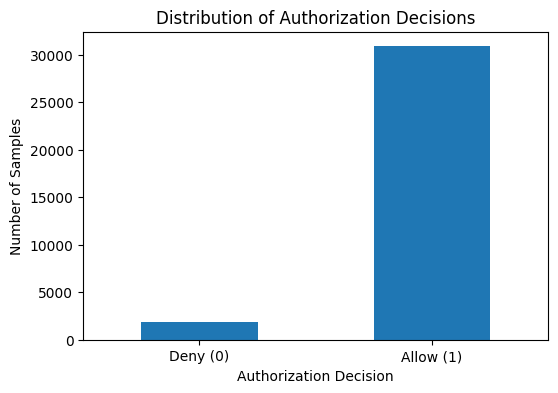

Allow samples: 30872
Deny samples: 1897
Allow percentage: 94.21%
Deny percentage: 5.79%


In [ ]:
print("Authorization decision distribution:")
print(df["ACTION"].value_counts())

class_counts = df["ACTION"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Distribution of Authorization Decisions")
plt.xlabel("Authorization Decision")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Deny (0)", "Allow (1)"], rotation=0)
plt.show()

allow_count = class_counts.get(1, 0)
deny_count = class_counts.get(0, 0)
print(f"Allow samples: {allow_count}")
print(f"Deny samples: {deny_count}")
print(f"Allow percentage: {allow_count / len(df) * 100:.2f}%")
print(f"Deny percentage: {deny_count / len(df) * 100:.2f}%")

### Why this matters for Cloud CI security

If a model predicts **Allow** for almost every request, it may still show high accuracy because most requests in the historical data are allowed.

However, in authorization systems, the dangerous error is:

> Actual Deny → Predicted Allow

This means an unauthorized request was granted access. In this notebook, this is captured using **False Positive Rate (FPR)** when **Allow** is treated as the positive class.

Therefore, we will not rely only on accuracy. We will also evaluate:

- Precision
- Recall / TPR
- F1-score
- FPR
- Deny Recall
- Balanced Accuracy

## 5. Feature selection

Feature selection identifies the variables used as inputs to the model.

In this dataset:

- `ACTION` is the target label, representing the authorization decision.
- All other columns are input features, representing authorization metadata.

In a real Cloud CI environment, these features could correspond to principal metadata, resource metadata, role information, workflow context, or project/team information.

In [ ]:
# Separate input features from the target authorization decision.
X = df.drop("ACTION", axis=1)
y = df["ACTION"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (32769, 9)
Target vector shape: (32769,)


## 6. Train/test split

Machine learning models must be evaluated on data they did not see during training.

We split the historical authorization records into:

- **Training set:** used to learn authorization behavior.
- **Testing set:** used to simulate future unseen authorization requests.

Important: imbalance handling is applied only to the training process. The test set remains untouched so that evaluation reflects the original real-world distribution.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 26215
Testing samples: 6554

Training class distribution:
ACTION
1    24697
0     1518
Name: count, dtype: int64

Testing class distribution:
ACTION
1    6175
0     379
Name: count, dtype: int64


## 7. Feature engineering and scaling

Feature engineering prepares authorization metadata for machine learning.

The Amazon Employee Access dataset already provides anonymized numerical/categorical codes, so we do not need to manually encode strings in this lab.

However, some models, especially SVMs and neural networks, benefit from scaled input features. Scaling transforms the features so that they are on a comparable numerical scale.

Decision Trees and Random Forests are less sensitive to scaling, but we use the scaled data consistently for all models in this notebook.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed.
Scaled training shape: (26215, 9)
Scaled testing shape: (6554, 9)


## 8. Evaluation helpers

In ordinary ML tasks, accuracy is often emphasized. In authorization systems, this is not enough.

Here, we compute:

- **Accuracy:** overall correctness.
- **Precision:** of predicted Allows, how many were truly Allow.
- **Recall/TPR:** of true Allows, how many were predicted Allow.
- **F1:** harmonic mean of precision and recall.
- **FPR:** of true Deny requests, how many were incorrectly predicted Allow.
- **Deny Recall:** of true Deny requests, how many were correctly denied.
- **Balanced Accuracy:** average of Allow recall and Deny recall.

For Cloud CI security, **FPR** is especially important because it measures false authorization approval.

In [ ]:
def calculate_fpr(y_true, y_pred):
    """
    False Positive Rate when Allow = 1 is the positive class.

    FPR = FP / (FP + TN)

    In this lab:
    FP means Actual Deny but Predicted Allow.
    This is a security-critical false approval.
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp / (fp + tn) if (fp + tn) > 0 else 0


def calculate_deny_recall(y_true, y_pred):
    """
    Deny Recall measures how many true Deny requests were correctly denied.

    Deny Recall = TN / (TN + FP)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0


def evaluate_predictions(y_true, y_pred):
    """
    Return a dictionary of security-oriented evaluation metrics.
    """
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall/TPR": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "FPR": calculate_fpr(y_true, y_pred),
        "Deny Recall": calculate_deny_recall(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred)
    }


def evaluate_sklearn_model(model, X_test_data, y_test_data):
    y_pred = model.predict(X_test_data)
    return evaluate_predictions(y_test_data, y_pred), y_pred

## 9. Experiment 1 — Training on the original imbalanced dataset

In this experiment, we train models directly on the original historical authorization records.

This represents the baseline case: no imbalance handling is applied.

The goal is to observe whether models become biased toward the majority **Allow** class.

In [ ]:
# TODO 5: Review these original models. They do not use class_weight.
# Use n_estimators = n_estimators=100, random_state=42, n_jobs=-1, max_iter=5000
models_original = {
    "Decision Tree - Original": DecisionTreeClassifier(random_state=42),
    "Random Forest - Original": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Linear SVM - Original": LinearSVC(random_state=42, max_iter=5000)
}

original_ml_results = {}
original_ml_predictions = {}
original_ml_models = {}

for name, model in models_original.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    metrics, preds = evaluate_sklearn_model(model, X_test_scaled, y_test)
    original_ml_results[name] = metrics
    original_ml_predictions[name] = preds
    original_ml_models[name] = model

original_ml_results_df = pd.DataFrame(original_ml_results).T
original_ml_results_df

Training Decision Tree - Original...
Training Random Forest - Original...
Training Linear SVM - Original...


,Accuracy,Precision,Recall/TPR,F1,FPR,Deny Recall,Balanced Accuracy
Decision Tree - Original,0.927373,0.964921,0.957733,0.961313,0.567282,0.432718,0.695225
Random Forest - Original,0.947208,0.960936,0.983968,0.972316,0.651715,0.348285,0.666126
Linear SVM - Original,0.942173,0.942173,1.000000,0.970225,1.000000,0.000000,0.500000


## 10. Experiment 2 — Cost-sensitive learning with `class_weight="balanced"`

In this experiment, we preserve the original dataset but change how the model treats mistakes.

`class_weight="balanced"` automatically gives more weight to the minority class. This means that mistakes on the **Deny** class receive a larger penalty during training.

This is useful for authorization because incorrectly allowing a denied request is security-critical.

Important:

- We do not remove any Allow samples.
- We do not generate synthetic Deny samples.
- We preserve the original historical authorization records.
- We change the learning objective so the model pays more attention to Deny examples.

In [ ]:
# TODO 6: Notice class_weight="balanced" in each model. Other parameters same as above.
models_balanced = {
    "Decision Tree - Balanced": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest - Balanced": RandomForestClassifier(),
    "Linear SVM - Balanced": LinearSVC()
}

balanced_ml_results = {}
balanced_ml_predictions = {}
balanced_ml_models = {}

for name, model in models_balanced.items():
    print(f"Training {name}...")
    # TODO 7:
    # Train the model.
    # Evaluate the trained model.
    # Store the metrics, predictions, and trained model.

# TODO 8:
# Convert the results dictionary into a pandas DataFrame and display it.

## 11. Comparing original vs balanced machine learning models

This table compares the baseline models and the class-weighted models.

A model may have slightly lower accuracy after balancing, but it may better identify the minority Deny class. In security, this trade-off can be valuable because false approvals are dangerous.

In [ ]:
ml_comparison_df = pd.concat([original_ml_results_df, balanced_ml_results_df])
ml_comparison_df.sort_values(by="Balanced Accuracy", ascending=False)

In [ ]:
# Visual comparison of selected security metrics.
selected_metrics = ["Accuracy", "F1", "FPR", "Deny Recall", "Balanced Accuracy"]

ml_comparison_df[selected_metrics].plot(kind="bar", figsize=(14, 6))
plt.title("Original vs Balanced ML Models")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

## 12. Confusion matrix comparison

The confusion matrix helps us understand model behavior:

| Outcome | Meaning in authorization |
|---|---|
| True Positive | Actual Allow, predicted Allow |
| True Negative | Actual Deny, predicted Deny |
| False Positive | Actual Deny, predicted Allow — dangerous false approval |
| False Negative | Actual Allow, predicted Deny — legitimate access blocked |

The most security-critical case is **False Positive**, where an access request that should be denied is incorrectly allowed.

In [ ]:
def plot_confusion_matrix_for_predictions(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted Deny", "Predicted Allow"],
        yticklabels=["Actual Deny", "Actual Allow"]
    )
    plt.title(title)
    plt.xlabel("Prediction")
    plt.ylabel("Actual")
    plt.show()

# Plot confusion matrices for the best original and best balanced ML models.
best_original_ml_name = original_ml_results_df["Balanced Accuracy"].idxmax()
best_balanced_ml_name = balanced_ml_results_df["Balanced Accuracy"].idxmax()

print("Best original ML model:", best_original_ml_name)
plot_confusion_matrix_for_predictions(
    y_test,
    original_ml_predictions[best_original_ml_name],
    best_original_ml_name
)

print("Best balanced ML model:", best_balanced_ml_name)
plot_confusion_matrix_for_predictions(
    y_test,
    balanced_ml_predictions[best_balanced_ml_name],
    best_balanced_ml_name
)

## 13. Deep Learning authorization engine

The lecture introduces Deep Learning Based Access Control (DLBAC), where authorization decisions are learned from authorization tuples and metadata.

In this lab, we implement a simple Multi-Layer Perceptron (MLP). This is not intended to reproduce the exact ResNet/DenseNet/Xception architectures from the research presentation. Instead, it gives students a clear and runnable deep learning model in Google Colab.

The model receives authorization metadata as input and predicts:

- `1` → Allow
- `0` → Deny

In [ ]:
def build_mlp(input_dim):
    """
    Build a simple neural network for binary authorization prediction.

    Architecture:
    Input features -> Dense layers -> Sigmoid output

    The sigmoid output produces a probability between 0 and 1.
    A value >= 0.5 is interpreted as Allow.
    A value < 0.5 is interpreted as Deny.
    """
    model = Sequential([
        Dense(128, activation="relu", input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.30),

        Dense(64, activation="relu"),
        Dropout(0.30),

        Dense(32, activation="relu"),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


def evaluate_deep_learning_model(model, X_test_data, y_test_data, threshold=0.5):
    """
    Evaluate a trained MLP model.
    """
    y_prob = model.predict(X_test_data, verbose=0).flatten()
    y_pred = (y_prob >= threshold).astype(int)
    return evaluate_predictions(y_test_data, y_pred), y_pred

## 14. Experiment 3 — Original deep learning model

First, we train the neural network on the original imbalanced training data.

This allows us to compare deep learning behavior with the classical ML baselines.

In [ ]:
early_stop_original = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# TODO 9: Train the original MLP without class weights. Fill the .fit() function with arguments
mlp_original = build_mlp(X_train_scaled.shape[1])

history_original = mlp_original.fit()

mlp_original_metrics, mlp_original_pred = evaluate_deep_learning_model(
    mlp_original,
    X_test_scaled,
    y_test
)

In [ ]:
pd.DataFrame({"MLP - Original": mlp_original_metrics}).T

## 15. Experiment 4 — Balanced deep learning model using weighted loss

For deep learning, we do not use `class_weight="balanced"` inside a model constructor.

Instead, we compute class weights from the training labels and pass them to `model.fit()`.

This makes the neural network place larger training penalties on mistakes involving the minority **Deny** class.

In [ ]:
classes = np.unique(y_train)

# TODO 10: Compute class weights for the training labels. Fill the function with arguments
weights = compute_class_weight()

class_weights = dict(zip(classes, weights))

print("Computed class weights for deep learning:")
print(class_weights)

In [ ]:
early_stop_balanced = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

mlp_balanced = build_mlp(X_train_scaled.shape[1])

history_balanced = mlp_balanced.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.20,
    callbacks=[early_stop_balanced],
    # TODO 11: class_weight tells Keras to penalize Deny mistakes more.
    class_weight=,
    verbose=1
)

mlp_balanced_metrics, mlp_balanced_pred = evaluate_deep_learning_model(
    mlp_balanced,
    X_test_scaled,
    y_test
)

In [ ]:
pd.DataFrame({"MLP - Balanced": mlp_balanced_metrics}).T

In [ ]:
# Plot training history for original and balanced MLP models.
plt.figure(figsize=(10, 5))
plt.plot(history_original.history["loss"], label="Original Training Loss")
plt.plot(history_original.history["val_loss"], label="Original Validation Loss")
plt.plot(history_balanced.history["loss"], label="Balanced Training Loss")
plt.plot(history_balanced.history["val_loss"], label="Balanced Validation Loss")
plt.title("MLP Training History")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.show()

## 16. Final comparison — ML vs DL, original vs balanced

This final table compares all models:

- Classical ML on original data
- Classical ML with class weighting
- MLP on original data
- MLP with weighted loss

The key lesson is that the best authorization model is not necessarily the model with the highest accuracy. In security, we must also consider false approvals and the ability to correctly identify Deny requests.

In [ ]:
dl_results_df = pd.DataFrame({
    "MLP - Original": mlp_original_metrics,
    "MLP - Balanced": mlp_balanced_metrics
}).T

final_results_df = pd.concat([
    original_ml_results_df,
    balanced_ml_results_df,
    dl_results_df
])

final_results_df.sort_values(by="Balanced Accuracy", ascending=False)

In [ ]:
selected_metrics = ["Accuracy", "F1", "FPR", "Deny Recall", "Balanced Accuracy"]

final_results_df[selected_metrics].plot(kind="bar", figsize=(15, 7))
plt.title("Final Model Comparison: Original vs Balanced Training")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

## 17. Detailed report for the best model

The classification report shows performance for both classes separately.

This is useful because a model may perform well on the majority Allow class but poorly on the minority Deny class.

In [ ]:
# Select the model with the highest Balanced Accuracy.
best_model_name = final_results_df["Balanced Accuracy"].idxmax()
print("Best model based on Balanced Accuracy:", best_model_name)

if best_model_name in original_ml_predictions:
    best_pred = original_ml_predictions[best_model_name]
elif best_model_name in balanced_ml_predictions:
    best_pred = balanced_ml_predictions[best_model_name]
elif best_model_name == "MLP - Original":
    best_pred = mlp_original_pred
else:
    best_pred = mlp_balanced_pred

print(classification_report(
    y_test,
    best_pred,
    target_names=["Deny", "Allow"],
    zero_division=0
))

plot_confusion_matrix_for_predictions(
    y_test,
    best_pred,
    f"Confusion Matrix: {best_model_name}"
)

## 18. Prediction as automated authorization

The trained model can now be interpreted as an AI-assisted authorization engine.

In a Cloud CI system, a future request might come from:

- a developer
- a GitHub Actions workflow
- a service account
- a Kubernetes workload

The model predicts whether a request should be allowed or denied based on historical authorization patterns.

In [ ]:
# Display a few unseen test records and their predicted authorization decisions.
sample_requests = X_test.iloc[:10].copy()
sample_predictions = best_pred[:10]

sample_output = sample_requests.copy()
sample_output["Predicted Decision"] = sample_predictions
sample_output["Predicted Decision Label"] = sample_output["Predicted Decision"].map({
    0: "Deny",
    1: "Allow"
})

sample_output

## 19. Reflection questions

Answer the following questions:

1. Why is the Amazon Employee Access dataset imbalanced?
2. Why can high accuracy be misleading in authorization systems?
3. What does False Positive Rate mean in this lab?
4. Why is Actual Deny → Predicted Allow dangerous in Cloud CI?
5. How did class weighting affect model performance?
6. Did balanced training improve Deny Recall or Balanced Accuracy?
7. Which model would you recommend for an AI-assisted authorization system, and why?
8. Should AI fully replace IAM policies? Why or why not?
9. How could this approach support least-privilege access control?
10. What risks might occur if historical authorization data contains incorrect approvals?


Write your answers below each question in your submitted notebook.

## 20. Optional advanced research extension: SMOTENC

This lab uses class weighting as the primary imbalance-handling technique because it preserves the original authorization records.

An alternative research-oriented method is **SMOTENC**, which creates synthetic minority-class examples for datasets containing categorical features.

SMOTENC can be useful, but it also introduces a stronger assumption: synthetic authorization records are treated as if they are meaningful examples. In security-sensitive access control, this assumption should be evaluated carefully.

Recommended extension:

1. Apply SMOTENC only to the training set.
2. Retrain Random Forest and MLP models.
3. Evaluate on the original untouched test set.
4. Compare SMOTENC with class weighting.
5. Discuss which method is more appropriate for production Cloud CI authorization.

## 21. Deliverables

Submit the following:

1. Completed Google Colab notebook (`.ipynb`).
2. Class distribution plot.
3. Original vs balanced model comparison table.
4. Confusion matrix for the best original model and best balanced model.
5. Final ML vs DL comparison table.
6. Answers to the reflection questions.

No VM, container, CyberRange, or local setup is required.